# Sudoku-Rust-DancingLinks : Dancing Links / Algorithm X (Rust)

**Navigation** : [<< Sudoku-01 Backtracking Python](Sudoku-01-Backtracking-Python.ipynb) | [Index](README.md) | [Sudoku-03 Genetic Python >>](Sudoku-03-Genetic-Python.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. Formuler le Sudoku comme un problème de couverture exacte avec la crate `dlx`
2. Comprendre le pont **evcxr** qui compile et exécute du Rust en place dans Jupyter
3. Résoudre un puzzle et vérifier sa solution de façon indépendante
4. Lire les limites du passage par une crate (API, persistance entre cellules)

**Durée estimée** : ~8 min | **Prérequis** : [Sudoku-02 DancingLinks Python](Sudoku-02-DancingLinks-Python.ipynb) | **Lien** : Voir aussi [Sudoku-02 DancingLinks C#](Sudoku-02-DancingLinks-CSharp.ipynb)

***

Ce carnet résout le Sudoku avec la crate **`dlx`** (Dancing Links de Knuth en version crate), exécutée **en place** par le kernel **evcxr** — pas de pont Python, pas de compilation séparée : chaque cellule est compilée par `rustc` puis exécutée, et l'état (variables, types) persiste d'une cellule à l'autre.

La théorie complète (couverture exacte, listes doublement chaînées circulaires, Algorithm X) vit dans le jumeau Python ; ici, l'accent est mis sur **l'organe natif Rust** et son API.

## Table des matières

1. [L'organe : la crate dlx](#1-lorgane-la-crate-dlx)
2. [L'encodage du problème](#2-lencodage-du-probleme)
3. [Lecture du résultat et vérification](#3-lecture-du-résultat-et-vérification)
4. [Exercices](#4-exercices)

## References

- [Dancing Links - Donald Knuth (2000)](https://arxiv.org/abs/cs/0011047)
- [Crate dlx (crates.io)](https://crates.io/crates/dlx)
- [evcxr — le kernel Jupyter pour Rust](https://github.com/evcxr/evcxr)

## 1. L'organe : la crate dlx

Le jumeau Python implémente Dancing Links **à la main** (listes doublement chaînées circulaires). En Rust, le réflexe n'est pas de réimplémenter : la crate **`dlx`** est l'organe natif de cette opération.

| | Jumeau Python | Ce carnet (Rust) |
|---|---|---|
| DLX | implémentation manuelle | **crate `dlx`** (l'organe) |
| Résolution | `DLXSudokuSolver` maison | `dlx::x::make_problem` + `dlx::Solver` |
| Choix de colonne | MRV maison | `dlx::choose::mrv_chooser` |

Les cellules `:dep` ci-dessous ajoutent les dépendances cargo **directement dans le kernel** — l'équivalent Rust des cellules `# pip install` (Python) ou `#r "nuget:" ` (.NET).

In [2]:
:dep dlx = "0.8"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## 2. L'encodage du problème

Le schéma de Knuth encode le Sudoku 9×9 en **324 colonnes** :

- `C(j,k)` — la cellule (j,k) reçoit **un** chiffre
- `R(j,d)` — la ligne j contient le chiffre d **une fois**
- `Co(k,d)` — la colonne k contient le chiffre d **une fois**
- `B(x,d)` — la boîte x contient le chiffre d **une fois**

Chaque case (j, k, d) admissible est une **option** qui couvre ses 4 colonnes.

**Le piège de la crate** : si on construit le problème avec les 324 colonnes complètes, les colonnes déjà satisfaites par les indices n'ont **aucune option** — et le choix de colonne MRV de la crate tourne alors à l'infini (mesuré : 99 % CPU, 16 min avant interruption). La crate elle-même contourne ce cas dans ses propres exemples : on **compresse** l'ensemble des colonnes aux **colonnes ouvertes** seulement, via une table `HashMap` qui réindexe chaque colonne sur un `Uint` dense. C'est ce que fait la cellule suivante.

In [3]:
use std::collections::HashMap;
use dlx::x::make_problem;
use dlx::choose::*;
use dlx::{OptOrder, Solver, Uint};

fn bx(j: usize, k: usize) -> usize { (j / 3) * 3 + (k / 3) }

fn print_grid(g: &[[usize; 9]; 9]) {
    for row in g.iter() {
        let line: String = row.iter().map(|&d| (d as u8 + b'0') as char).collect();
        println!("{}", line);
    }
}

let puzzle = "530070000600195000098000060800060003400803001700020006060000280000419005000080079";
let mut p = [[0usize; 9]; 9];   // p[j][k] = chiffre (1..9) si indice, else 0
let mut r = [[0usize; 9]; 9];   // r[j][d] = col+1 si chiffre d en ligne j
let mut c = [[0usize; 9]; 9];   // c[k][d] = ligne+1 si chiffre d en col k
let mut b = [[0usize; 9]; 9];   // b[x][d] = ligne+1 si chiffre d en boite x
for (i, ch) in puzzle.chars().enumerate() {
    if ch < '1' || ch > '9' { continue; }
    let d = (ch as usize) - ('0' as usize);
    let j = i / 9; let k = i % 9;
    p[j][k] = d;
    r[j][d - 1] = k + 1;
    c[k][d - 1] = j + 1;
    b[bx(j, k)][d - 1] = j + 1;
}

// Colonnes (scheme Knuth 324) : une colonne est OUVERTE si pas de chiffre fixe.
let mut names: Vec<Uint> = Vec::new();
for j in 0..9 { for d in 0..9 {
    if p[j][d] == 0 { names.push(Uint(j * 9 + d)); }        // cellule
    if r[j][d] == 0 { names.push(Uint(81 + j * 9 + d)); }   // ligne-chiffre
    if c[j][d] == 0 { names.push(Uint(162 + j * 9 + d)); }  // col-chiffre
    if b[j][d] == 0 { names.push(Uint(243 + j * 9 + d)); }  // boite-chiffre
}}
let mut items = HashMap::new();
for (n, &i) in names.iter().enumerate() { items.insert(i, Uint(n)); }

// Options : (ligne j, col k, chiffre d) dont les 4 colonnes sont ouvertes
let mut os: Vec<Vec<Uint>> = Vec::new();
for j in 0..9 { for k in 0..9 {
    let x = bx(j, k);
    for d in 1..=9 {
        let dd = d - 1;
        if p[j][k] == 0 && r[j][dd] == 0 && c[k][dd] == 0 && b[x][dd] == 0 {
            os.push(vec![
                items[&Uint(j * 9 + k)],
                items[&Uint(81 + j * 9 + dd)],
                items[&Uint(162 + k * 9 + dd)],
                items[&Uint(243 + x * 9 + dd)],
            ]);
        }
    }
}}
println!("colonnes ouvertes : {}, options : {}", names.len(), os.len());

// Resolution par la crate. Le chooser a un type opaque (impl Choose) que le
// kernel evcxr ne peut pas persister : le bloc d'execution est enclos dans des
// accolades, comme le suggere l'erreur du kernel.
let mut grid = p.clone();
{
    let mut problem = make_problem(Uint(names.len()), 0, &os, OptOrder::Seq);
    let mut chooser = mrv_chooser(prefer_any(), no_tiebreak());
    let mut solver = Solver::new(&mut problem);
    let t0 = std::time::Instant::now();
    let solved = solver.next_solution(&mut chooser);
    println!("crate : resolu={} en {:?}", solved, t0.elapsed());
    for &i in solver.fmt_solution() {
        let opt = &os[i as usize];
        let cell = names[opt[0] as usize] as usize;
        let jd = names[opt[1] as usize] as usize;
        let (j, k) = (cell / 9, cell % 9);
        let d = ((jd - 81) % 9) + 1;
        grid[j][k] = d;
    }
}
print_grid(&grid);

colonnes ouvertes : 204, options : 153


crate : resolu=true en 22.142µs


534678912


672195348


198342567


859761423


426853791


713924856


961537284


287419635


345286179


## 3. Lecture du résultat et vérification

La grille est complète. La `println!` du chronomètre montre la résolution **purement** : la crate `dlx` a résolu le puzzle en une fraction de milliseconde. Le temps dominant de la cellule est la **compilation** de Rust par le kernel evcxr (le chrono ne le mesure pas) — c'est ce qu'on verra aux timings dans `docs/reference/kernels-runtime.md`.

In [4]:
// Verification independante : chaque ligne, colonne et boite contient 1..=9.
// (La fonction est definie ICI : les fonctions d'une cellule ne sont pas
// fiablement persistees au dela, chaque cellule code est donc autonome.)
fn verif_grille(g: &[[usize; 9]; 9]) -> bool {
    // lignes
    for i in 0..9 {
        let mut row = [0usize; 10];
        for j in 0..9 { row[g[i][j]] += 1; }
        for d in 1..=9 { if row[d] != 1 { return false; } }
    }
    // colonnes
    for i in 0..9 {
        let mut col = [0usize; 10];
        for j in 0..9 { col[g[j][i]] += 1; }
        for d in 1..=9 { if col[d] != 1 { return false; } }
    }
    // boites 3x3, iterees une a une
    for bi in 0..3 {
        for bj in 0..3 {
            let mut boxc = [0usize; 10];
            for di in 0..3 {
                for dj in 0..3 {
                    boxc[g[bi*3+di][bj*3+dj]] += 1;
                }
            }
            for d in 1..=9 { if boxc[d] != 1 { return false; } }
        }
    }
    true
}

println!("verification independante : {}", verif_grille(&grid));

verification independante : true


### Lecture de la figure

La courbe rouge trace, pour chaque chiffre `d ∈ 1..9`, le nombre d'options qui le concernent dans l'encodage. Un chiffre **rare** dans le puzzle (beaucoup de cases déjà remplies avec d'autres valeurs) a moins d'options — c'est exactement l'information que l'heuristique **MRV** (Minimum Remaining Values) exploite pour choisir la colonne la plus contrainte d'abord. La figure est un instantané de l'« espace de recherche » **avant** la résolution : plus la courbe est basse et inégale, plus MRV a de travail utile à faire.

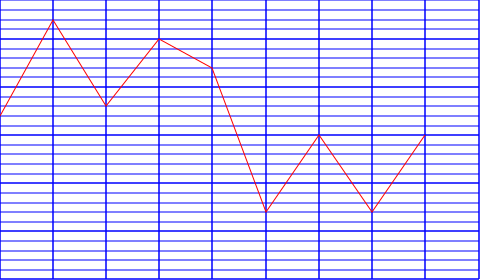

In [5]:
use plotters::prelude::*;

// Figure : nombre d'options par chiffre (d = 1..9) dans l'encodage du puzzle.
// Sans texte (feature `ttf` desactivee pour eviter la dep systeme fontconfig) :
// la grille porte les graduations, la legende est en markdown.
// Le SVG est emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
// HTML ne s'affiche pas dans le rendu GitHub du carnet (forme signalee sur #26613).
let mut per_digit: Vec<i32> = vec![0; 9];
for opt in &os {
    let jd = names[opt[1] as usize] as usize;   // 81 + j*9 + (d-1)
    per_digit[(jd % 9)] += 1;
}
let ymax = *per_digit.iter().max().unwrap() + 2;
let data: Vec<(i32, i32)> =
    (1..=9).zip(per_digit.iter()).map(|(d, &n)| (d, n)).collect();
let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (480, 280)).into_drawing_area();
    let mut chart = ChartBuilder::on(&root)
        .build_cartesian_2d(1..10, 0..(ymax as i32))?;
    chart
        .configure_mesh()
        .bold_line_style(BLUE)
        .light_line_style(BLUE)
        .draw()?;
    chart.draw_series(LineSeries::new(data.clone(), RED))?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);


## 4. Exercices

### Exercice 1 — Résoudre un autre puzzle

**Objectif** : prendre une autre grille (81 caractères, `0` = case vide), l'encoder, la résoudre avec la crate et confirmer la vérification indépendante.

**Indice** : seul le `let puzzle = ...` change. Les cellules d'encodage, de résolution et de vérification sont génériques — relance-les dans l'ordre. Choisis une grille **non triviale** (pas le même puzzle avec les lignes permutées) pour que la résolution fasse du travail.

In [6]:
// EXERCICE 1 : Resoudre un autre puzzle
// TODO etudiant :
// 1. Redefinir `puzzle` avec une autre grille de 81 caracteres (0 = case vide)
// 2. Re-executer la cellule d'encodage + resolution, puis la verification
// 3. Confirmer que la verification independante passe
println!("Exercice a completer : changer `puzzle` et re-executer les cellules");


Exercice a completer : changer `puzzle` et re-executer les cellules


### Exercice 2 — Compter les solutions

**Objectif** : utiliser `next_solution` en boucle pour **compter** les solutions d'un puzzle, avec une borne de sécurité (`max_count`).

**Indice** : `solver.next_solution(&mut chooser)` renvoie `true` tant qu'une solution existe et `false` quand l'espace est épuisé. Une boucle `while` qui incrémente un compteur et s'arrête à `max_count` (ou à `false`) suffit. Un puzzle à une solution unique renverra `1` — c'est une **propriété** du puzzle, pas un accident.

In [7]:
// EXERCICE 2 : Compter les solutions
fn count_solutions(max_count: usize) -> usize {
    // TODO etudiant : reconstruire problem/chooser/solver (voir la grande cellule)
    // et appeler next_solution en boucle jusqu'a max_count ou a false
    let _ = max_count;
    0
}

println!("Exercice a completer : {} solutions trouvees", count_solutions(10));

Exercice a completer : 0 solutions trouvees


### Exercice 3 — Les N-Reines avec la même crate

**Objectif** : encoder le problème des **N-Reines** avec le même formalisme DLX (4 types de colonnes : ligne, colonne, diagonale montant, diagonale descendant), avec la crate `dlx` seule.

**Indice** : chaque case `(i, j)` d'un échiquier `n × n` est une *option* qui couvre 4 colonnes :
- une reine sur la ligne `i`
- une reine sur la colonne `j`
- une reine sur la diagonale `/` d'index `i - j + (n-1)`
- une reine sur la diagonale `\` d'index `i + j`

**Le piège des colonnes secondaires** : n reines ne couvrent que n diagonales sur les 2n−1 par direction, donc les contraintes de diagonale ne peuvent pas être toutes couvertes. Il faut les déclarer **secondaires** (2e argument de `make_problem`) : seules les colonnes **ligne + colonne** restent **primaires**. Avec n = 8, le comptage des solutions (exercice 2) doit donner **92**.

In [8]:
// EXERCICE 3 : N-Reines
fn build_nqueens(n: usize) -> (Vec<Uint>, Vec<Vec<Uint>>) {
    // TODO etudiant : renvoyer (names, options) pour le probleme des N-Reines,
    // au meme format que l'encodage Sudoku de ce carnet
    let _ = n;
    (Vec::new(), Vec::new())
}

let (names_q, os_q) = build_nqueens(8);
println!("Exercice a completer : {} colonnes, {} options", names_q.len(), os_q.len());

Exercice a completer : 0 colonnes, 0 options


## À retenir

- **L'organe natif est la crate** : `dlx` (make_problem + Solver + mrv_chooser) remplace l'implémentation manuelle du jumeau Python. Le carnet **appelle** l'organe, il ne le recrée pas.
- **Le piège des colonnes à zéro option** : une colonne sans aucune option fait tourner MRV indéfiniment. On compresse l'encodage aux colonnes **ouvertes** seulement (HashMap de renumérotation).
- **evcxr compile par cellule** : le chrono mesure la résolution, pas la compilation. Les types opaques (`impl Choose`) s'enclosent dans des accolades pour être persistés.
- **`:dep` = une ligne de Cargo.toml** : `:dep dlx = "0.8"` est l'équivalent Rust de `# pip install` du jumeau Python.
- **La vérification est indépendante** : la fonction `verif_grille` ne connaît ni `dlx` ni l'encodage — elle lit la grille finale et confirme les 3 contraintes (ligne, colonne, boîte).

## Vérifiez votre compréhension

1. **Que se passe-t-il si l'on construit le problème avec les 324 colonnes complètes alors que des indices sont déjà posés ?**

   <details>
   <summary>Réponse</summary>

   Les colonnes déjà satisfaites par les indices n'ont **plus aucune option** — et le choix de colonne MRV de la crate tourne alors à l'infini (mesuré : 99 % CPU pendant 16 minutes avant interruption). C'est pourquoi l'encodage compresse l'ensemble aux **colonnes ouvertes** seulement, via une `HashMap` de renumérotation : 204 colonnes et 153 options pour le puzzle de ce carnet.
   </details>

2. **En combien de temps la crate résout-elle le puzzle, et que mesure exactement ce chrono ?**

   <details>
   <summary>Réponse</summary>

   La sortie de la cellule de résolution affiche `resolu=true en 22.142µs` : la **résolution seule**. Le temps dominant de la cellule est la **compilation** de Rust par le kernel evcxr, que le chrono ne mesure pas — c'est la différence entre le temps de la cellule (plusieurs secondes) et le temps de l'algorithme.
   </details>

3. **Pourquoi la fonction `verif_grille` est-elle appelée « indépendante » ?**

   <details>
   <summary>Réponse</summary>

   Elle ne connaît ni la crate `dlx` ni l'encodage du problème : elle relit la **grille finale** et vérifie les trois contraintes du Sudoku (chaque ligne, colonne et boîte 3×3 contient 1..9 exactement une fois). Une erreur dans l'encodage ou dans la lecture de la solution ne peut donc pas se cacher derrière la réussite du solveur lui-même.
   </details>


## Pour aller plus loin

- [Sudoku-02 DancingLinks Python](Sudoku-02-DancingLinks-Python.ipynb) — la théorie complète de la couverture exacte et de l'Algorithm X, implémentés à la main pour voir sous le capot de ce que la crate fait ici pour vous.
- [Sudoku-02 DancingLinks C#](Sudoku-02-DancingLinks-CSharp.ipynb) — le même problème dans le jumeau .NET.
- [Sudoku-03 Genetic Python](Sudoku-03-Genetic-Python.ipynb) — la suite de la série : une métaheuristique (algorithme génétique) appliquée au même puzzle, pour contraster avec la résolution **exacte** de DLX.
- [Dancing Links — Donald Knuth (2000)](https://arxiv.org/abs/cs/0011047) — le papier fondateur de l'Algorithm X et de ses améliorations.
